In [1]:
import pandas as pd   #dataframe
import matplotlib.pyplot as plt   #makes graphs
import numpy as np   #numerical data
import zipfile   #opens zipfile

from sklearn.model_selection import train_test_split   #splits data into training and testing
from sklearn.preprocessing import StandardScaler   #scales features on similar range

In [2]:
#Makes names for 32 columns

column_names = [
    "id", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean",
    "area_mean", "smoothness_mean", "compactness_mean",
    "concavity_mean", "concave_points_mean", "symmetry_mean",
    "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se",
    "area_se", "smoothness_se", "compactness_se",
    "concavity_se", "concave_points_se", "symmetry_se",
    "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst",
    "area_worst", "smoothness_worst", "compactness_worst",
    "concavity_worst", "concave_points_worst", "symmetry_worst",
    "fractal_dimension_worst"
]

with zipfile.ZipFile("breast+cancer+wisconsin+diagnostic.zip") as archive:   #opens zip file
    with archive.open("wdbc.data") as file:   #reads wdbc.data file
        df = pd.read_csv(file, header=None, names=column_names)   #loads data into pandas dataframe (df)

df.head()   #shows first five rows

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
df.info()   #shows information on number of rows/comumns, names, data types, if a column has a missing value or not

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
df.describe()   #shows mean, standard deviation, minimum and maximum values, quartiles

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [5]:
df.isnull().sum()   #checks columns for missing values

id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [6]:
df["diagnosis"].value_counts()   #shows if sample are benign or malignant

diagnosis
B    357
M    212
Name: count, dtype: int64

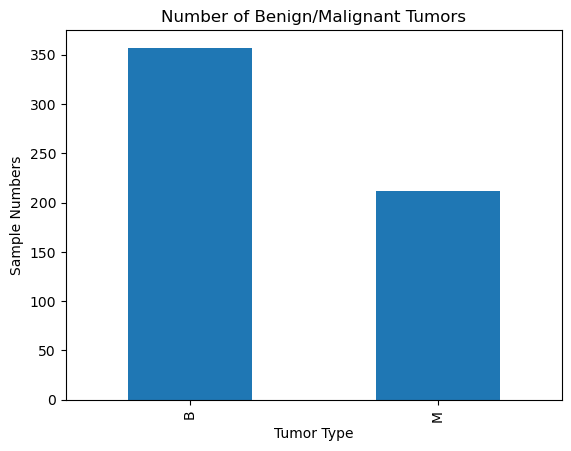

In [7]:
df["diagnosis"].value_counts().plot(kind = "bar")   #displays samples as a bar graph with .plot(kind = "bar")

plt.title("Number of Benign/Malignant Tumors")   #usual graph titles
plt.xlabel("Tumor Type")
plt.ylabel("Sample Numbers")

plt.show()   #displays bar graph

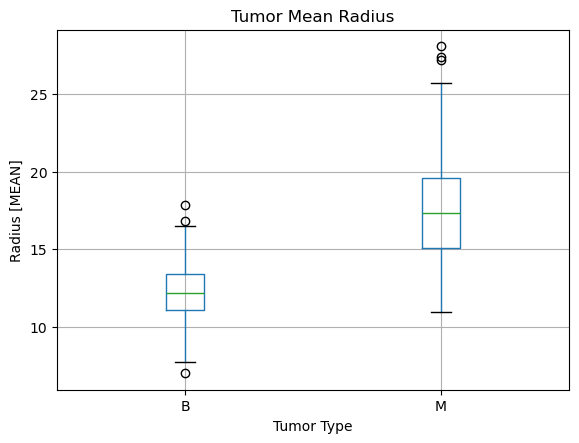

In [8]:
df.boxplot(column = "radius_mean", by = "diagnosis")   #turns info into a box graph. Shows measurements between benign and malignant

plt.title("Tumor Mean Radius")   #usual graph titles
plt.suptitle("")   #removes not neaded title
plt.xlabel("Tumor Type")
plt.ylabel("Radius [MEAN]")

plt.show()   #shows box plot graph   visualizes data to look for patterns and differences between the two groups

In [9]:
X = df.drop(["id", "diagnosis"], axis = 1)   #X holds 30 measurement columns for model/removes id
y = df["diagnosis"].map({"B": 0, "M": 1})   #y holds answers for model to learn/removes diagnosis for prediction

In [10]:
#splits data 80 - 20. 80% is training data to teach model, 20% is testing data to check model performance

X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size = 0.2,
random_state = 42,   #keeps split consistent
stratify = y   #keeps same proportion of samples (tumors)

)

In [11]:
scaler = StandardScaler()   #comparable scale for features
X_train_scaled = scaler.fit_transform(X_train)   #learns scaling from training data for application
X_test_scaled = scaler.transform(X_test)   #applies same scaling for testing data

In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000) #Creates the Logistic Regression Model

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

In [21]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.975


In [22]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.9285714285714286


In [23]:
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print (confusion)

Confusion Matrix:
[[71  1]
 [ 3 39]]
